# 02 — VCMA switching regimes

Using the corrected demagnetization factors ($N_x$ = 0.0122, $N_y$ = 0.0577, $N_z$ = 0.9301) this notebook maps how the free layer responds
to the pulse amplitude and the bias field. Each section reproduces a figure of the report.

| Regime | Voltage | Field |
|---|---|---|
| near-critical, low field | 4.8 V (just above $V_{xz}$ = 4.74 V) | $\mu_0H_x$ = 5 mT |
| high voltage, low field | 8.5 V (above $V_{yz}$ = 7.81 V) | $\mu_0H_x$ = 5 mT |
| high field | 0, 1.6, 3, 5 V ($V_\mathrm{crit}$ = 2.61 V) | $\mu_0H_x$ = 50 mT |
| VCMA-assisted field switching | 4.8 V | $\mu_0\mathbf{H}$ = (0.5, 0, −5) mT |

> 2 V across a 2 nm MgO barrier is already ≈1 V/nm, close to typical dielectric breakdown. The higher voltages map the macrospin regimes;
> they are not proposed operating points.

During the pulse $\alpha$ = 0.01; from 0.1 ns after the pulse ends $\alpha$ is raised to 0.1 so the post-pulse ring-down finishes quickly.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))   # use the repo copy without installing

import numpy as np
import matplotlib.pyplot as plt
import vcma_mtj as vm
from vcma_mtj import experiments as ex, plotting as vp
vp.apply_style(9)
DATA = pathlib.Path.cwd().parent / "data"
dev = vm.deng2017()

## 1. Effective anisotropy versus voltage

V_xz = 4.744 V   V_yz = 7.812 V   V(K_u=0) = 66.71 V


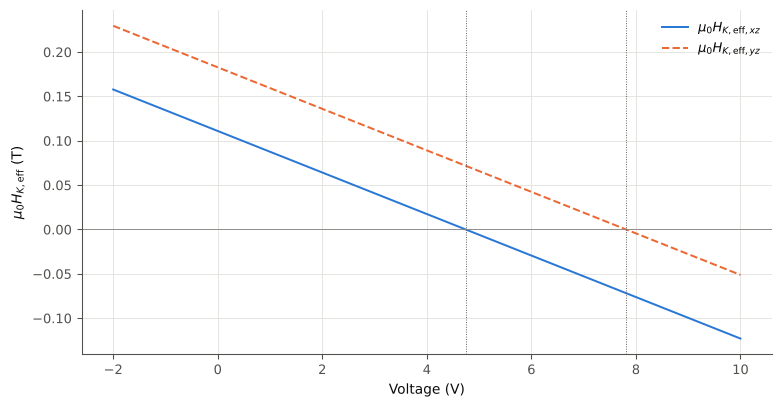

In [2]:
print(f"V_xz = {dev.V_xz:.3f} V   V_yz = {dev.V_yz:.3f} V   V(K_u=0) = {dev.V_Ku0:.2f} V")
V = np.linspace(-2, 10, 400)
fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
ax.plot(V, dev.BKeff_xz(V), label=r"$\mu_0H_{K,\mathrm{eff},xz}$")
ax.plot(V, dev.BKeff_yz(V), "--", label=r"$\mu_0H_{K,\mathrm{eff},yz}$")
ax.axhline(0, color=vp.MUTED, lw=0.6)
for v in (dev.V_xz, dev.V_yz): ax.axvline(v, color=vp.INK2, lw=0.6, ls=":")
ax.set(xlabel="Voltage (V)", ylabel=r"$\mu_0H_{K,\mathrm{eff}}$ (T)"); ax.legend();

Threshold in-plane field that flattens the $x$–$z$ barrier, $\mu_0 H_{x,\mathrm{th}}(V) = 2K_{\mathrm{eff},xz}(V)/M_s$ (Eq. 13),
and the easy-axis switching field of Eq. (14):

In [3]:
for V0 in (0, 2.5, 4.53, 4.8):
    print(f"V = {V0:4.2f} V:  mu0 H_x,th = {1e3*dev.B_threshold_x(V0):6.1f} mT   mu0 H_sw,z = {1e3*dev.B_switch_z(V0):6.1f} mT")

V = 0.00 V:  mu0 H_x,th =  111.0 mT   mu0 H_sw,z =  111.0 mT
V = 2.50 V:  mu0 H_x,th =   52.5 mT   mu0 H_sw,z =   52.5 mT
V = 4.53 V:  mu0 H_x,th =    5.0 mT   mu0 H_sw,z =    5.0 mT
V = 4.80 V:  mu0 H_x,th =    0.0 mT   mu0 H_sw,z =   -1.3 mT


## 2. Energy landscapes at zero field

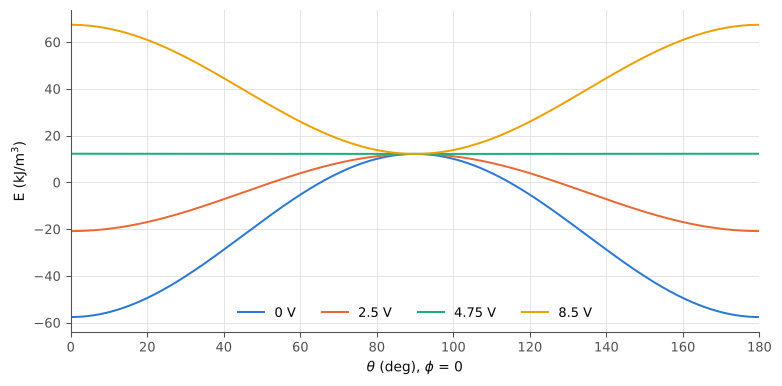

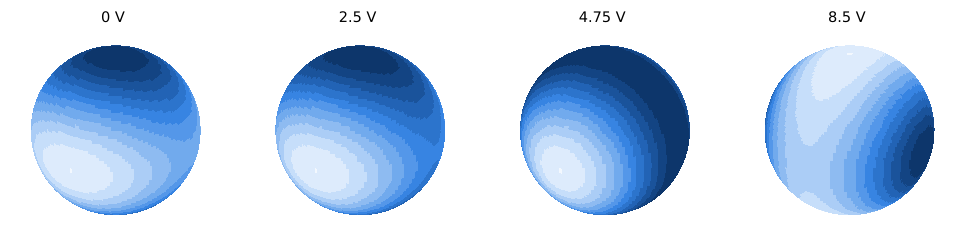

In [4]:
th = np.linspace(0, np.pi, 361)
m = vm.unit_vector(th, 0*th)
fig, ax = plt.subplots(figsize=(7, 3.4), layout="constrained")
for V0 in ex.LANDSCAPE_VOLTAGES:
    ax.plot(np.degrees(th), vm.energy_density(dev, m, V0)/1e3, label=f"{V0:g} V")
ax.set(xlabel=r"$\theta$ (deg), $\phi$ = 0", ylabel=r"E (kJ/m$^3$)", xlim=(0, 180)); ax.legend(ncol=4);

fig = plt.figure(figsize=(11, 2.8))
for k, V0 in enumerate(ex.LANDSCAPE_VOLTAGES):
    ax = fig.add_subplot(1, 4, k + 1, projection="3d"); vp.sphere(ax, dev, V0, n=100); ax.set_title(f"{V0:g} V")

## 3. Near-critical voltage, low field (4.8 V, 5 mT)

A long (9 ns) pulse reveals the precession period about the in-plane field.

mean precession period during the pulse: 1.85 ns


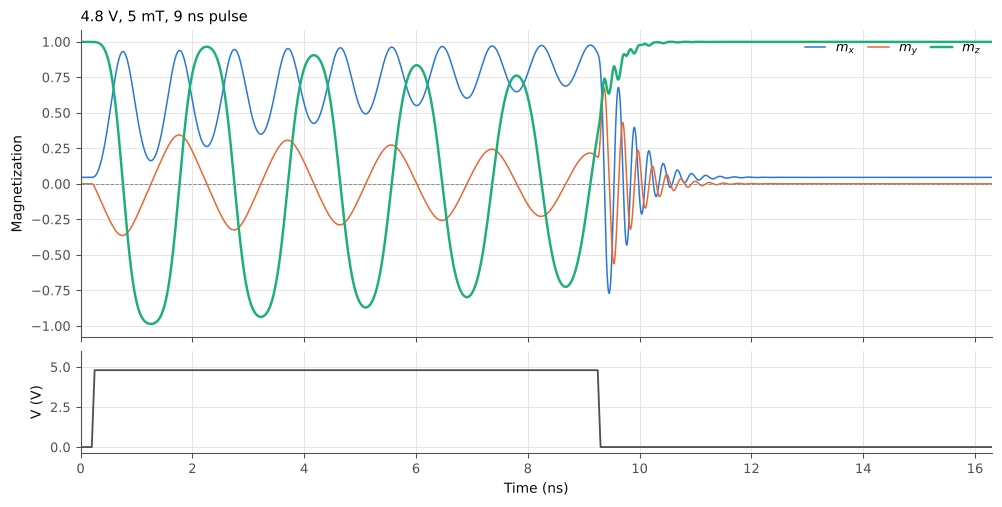

In [5]:
NC = ex.NearCritical()
r = ex.run_pulse(dev, NC.V0, NC.t_hold_long, (NC.Bx, 0, 0))
T = ex.measured_period(r, ex.T_START, ex.T_START + NC.t_hold_long)
print(f"mean precession period during the pulse: {T*1e9:.2f} ns")
vp.plot_dynamics(r, (9, 4.5), title="4.8 V, 5 mT, 9 ns pulse");

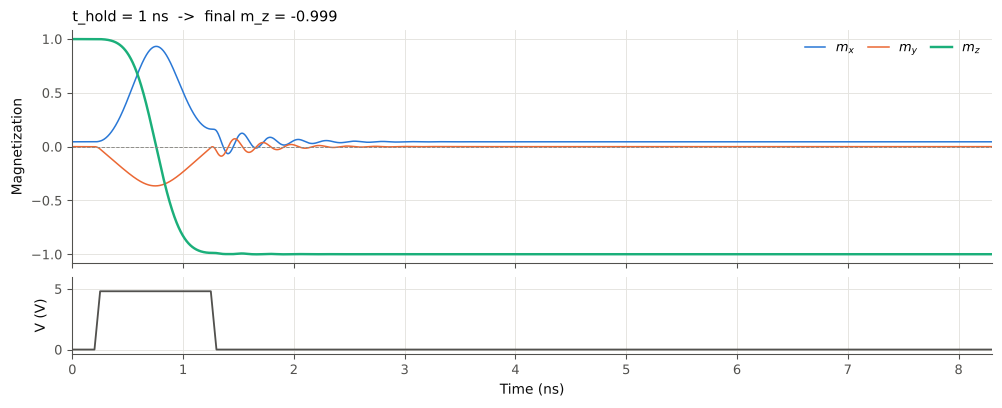

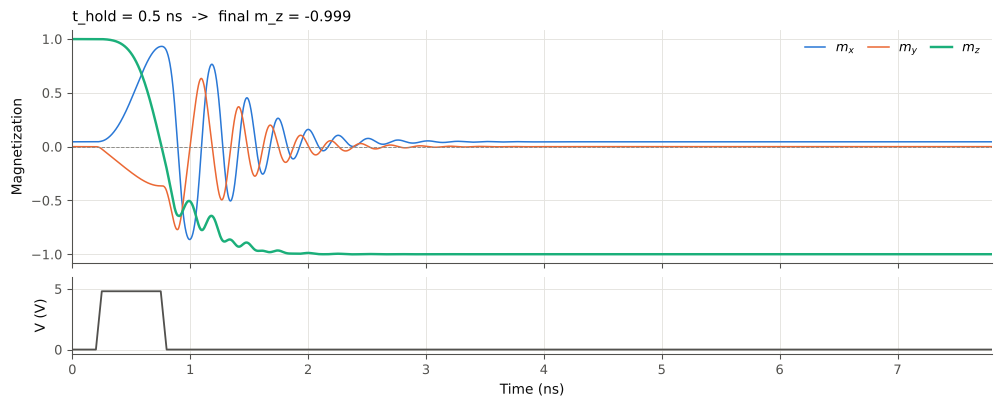

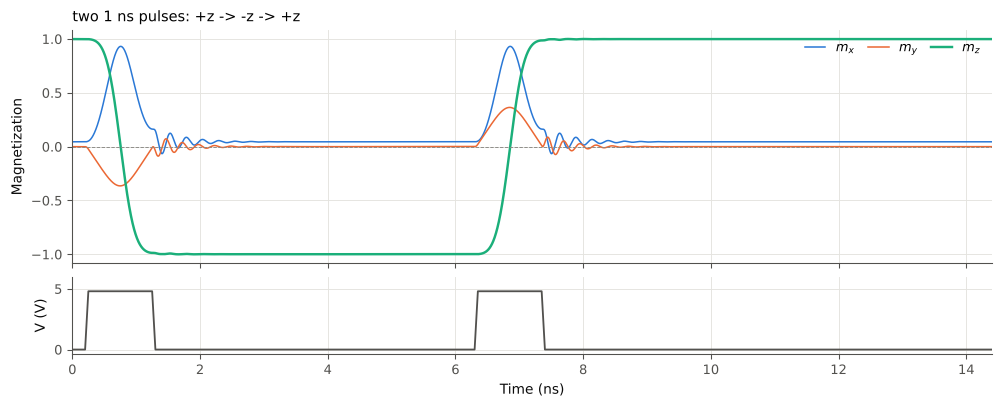

In [6]:
for th in (NC.t_hold_half, NC.t_hold_quarter):
    r = ex.run_pulse(dev, NC.V0, th, (NC.Bx, 0, 0))
    vp.plot_dynamics(r, (9, 3.6), title=f"t_hold = {th*1e9:g} ns  ->  final m_z = {r.final[2]:+.3f}")
r = ex.run_pulse(dev, NC.V0, NC.t_hold_half, (NC.Bx, 0, 0), double_gap=NC.gap)
vp.plot_dynamics(r, (9, 3.6), title="two 1 ns pulses: +z -> -z -> +z");

Switching windows: the layer switches when the pulse ends while $m$ is in the opposite hemisphere, i.e. for
$(n+\tfrac14)T < t < (n+\tfrac34)T$:

Shaded: where the simulation actually switched. Dashed: the rule, using the period fitted to the windows.
(The mean period on the single 9 ns pulse above is a little shorter, so it drifts off the windows after a few periods.)

windows (ns): [(0.42, 1.42), (2.42, 3.36), (4.32, 5.22)]
period fitted to the windows: 1.91 ns  (single-pulse mean: 1.85 ns)


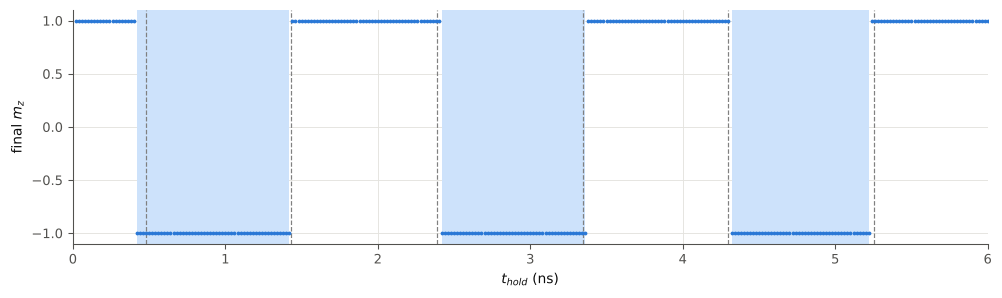

In [7]:
d = np.load(DATA / "nearcrit_window_scan.npz")
wins = ex.windows_from_scan(d["t_hold"], d["mz_final"])
Tw = ex.window_period(wins)
print("windows (ns):", [(round(float(a)*1e9, 2), round(float(b)*1e9, 2)) for a, b in wins])
print(f"period fitted to the windows: {Tw*1e9:.2f} ns  (single-pulse mean: {T*1e9:.2f} ns)")
fig, ax = plt.subplots(figsize=(9, 2.6), layout="constrained")
for a, b in wins: ax.axvspan(a*1e9, b*1e9, color="#cde2fb", lw=0)
for n in range(len(wins)):
    for f in (.25, .75): ax.axvline((n+f)*Tw*1e9, color="0.5", ls="--", lw=0.8)
ax.plot(d["t_hold"]*1e9, d["mz_final"], ".", ms=3)
ax.set(xlabel="$t_{hold}$ (ns)", ylabel="final $m_z$", xlim=(0, 6));

## 4. High voltage, low field (8.5 V, 5 mT)

Above $V_{yz}$ both out-of-plane barriers are inverted: $\pm z$ become maxima, $\pm x$ minima and $\pm y$ saddles.
$m$ spirals away from $+z$ around the $z$ axis, so switching is delayed by >13 ns.

case (i): t_hold = 25 ns, min m_z during pulse = -0.862, final m_z = -0.999


case (ii): t_hold = 18.4 ns, min m_z during pulse = +0.113, final m_z = -0.999


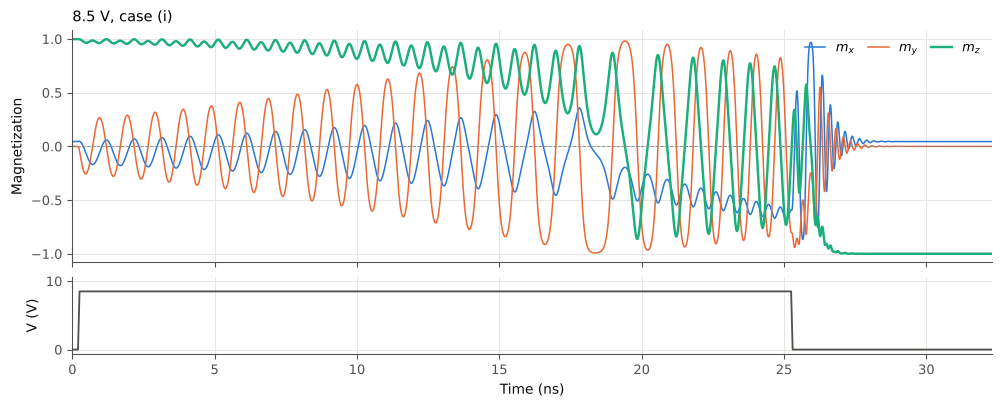

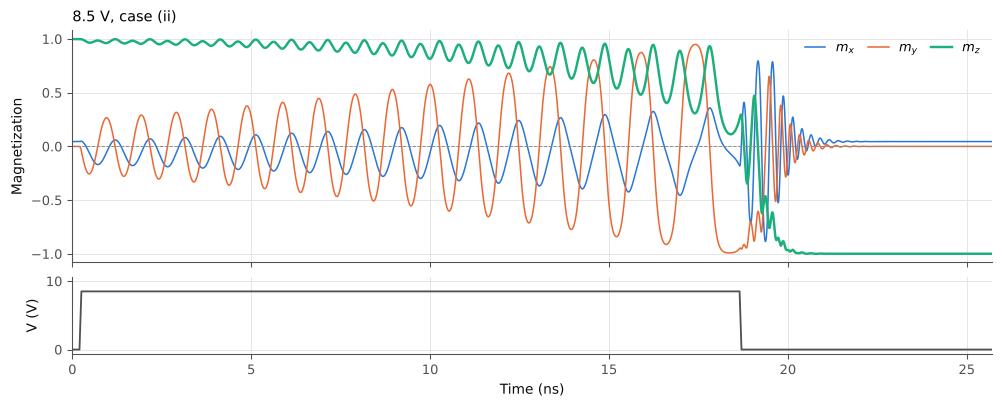

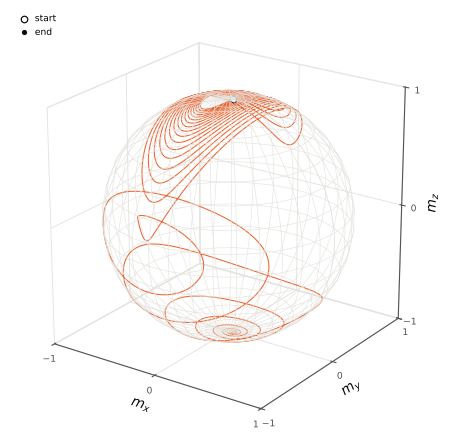

In [8]:
HV = ex.HighVoltage()
for th, case in ((HV.t_hold_case1, "i"), (HV.t_hold_case2, "ii")):
    r = ex.run_pulse(dev, HV.V0, th, (HV.Bx, 0, 0))
    print(f"case ({case}): t_hold = {th*1e9:g} ns, min m_z during pulse = {r.mz[r.t <= ex.T_START + th].min():+.3f}, final m_z = {r.final[2]:+.3f}")
    vp.plot_dynamics(r, (9, 3.6), title=f"8.5 V, case ({case})")
fig = plt.figure(figsize=(5, 5)); vp.trajectory_3d(fig.add_subplot(projection="3d"), r)

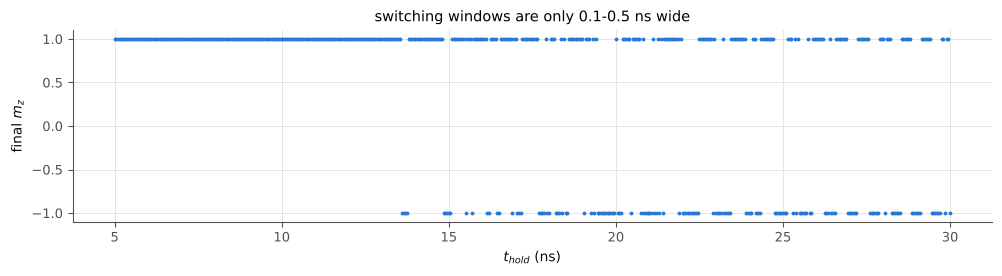

In [9]:
d = np.load(DATA / "highV_window_scan.npz")
fig, ax = plt.subplots(figsize=(9, 2.4), layout="constrained")
ax.plot(d["t_hold"]*1e9, d["mz_final"], ".", ms=3)
ax.set(xlabel="$t_{hold}$ (ns)", ylabel="final $m_z$", title="switching windows are only 0.1-0.5 ns wide");

## 5. High field (50 mT)

The field alone removes the barrier once $\mu_0H_{K,\mathrm{eff},xz}(V) < 50$ mT, i.e. above 2.61 V; above it $m$ orbits the $x$ axis.

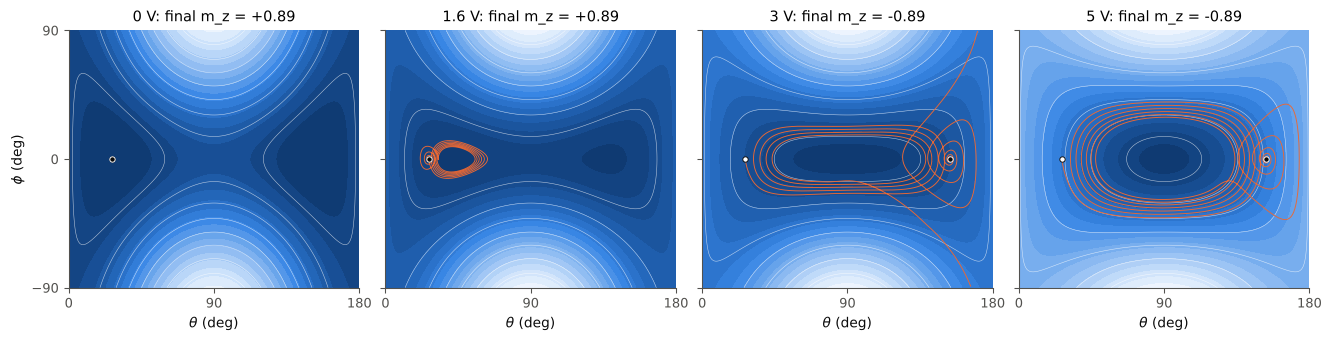

In [10]:
HF = ex.HighField(); bias = (HF.Bx, 0, 0)
m0 = vm.equilibrium(dev, 0, bias, +1)
fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharey=True, layout="constrained")
for ax, V0 in zip(axes, HF.voltages):
    r = ex.run_pulse(dev, V0, HF.t_hold, bias, m0=m0, post=4e-9)
    vp.landscape_2d(ax, dev, V0, bias, res=r); ax.set_title(f"{V0:g} V: final m_z = {r.final[2]:+.2f}")
    ax.set_xlabel(r"$\theta$ (deg)")
axes[0].set_ylabel(r"$\phi$ (deg)");

## 6. VCMA-assisted field-driven switching

Without a voltage, a $-z$ field must exceed $\mu_0H_{sw}(0)$ = 111 mT (Eq. 14). At 4.8 V this drops to about −1 mT, so a −5 mT field
(plus 0.5 mT along $x$ to break the symmetry) switches the layer, and the final state is set by the field, not by the pulse width.

mu0 H_sw(0) = 111.0 mT,  mu0 H_sw(4.8 V) = -1.3 mT


with -5 mT the outcome is -z for every pulse longer than 8.3 ns; without it the outcome keeps alternating (11 flips over 0-20 ns)


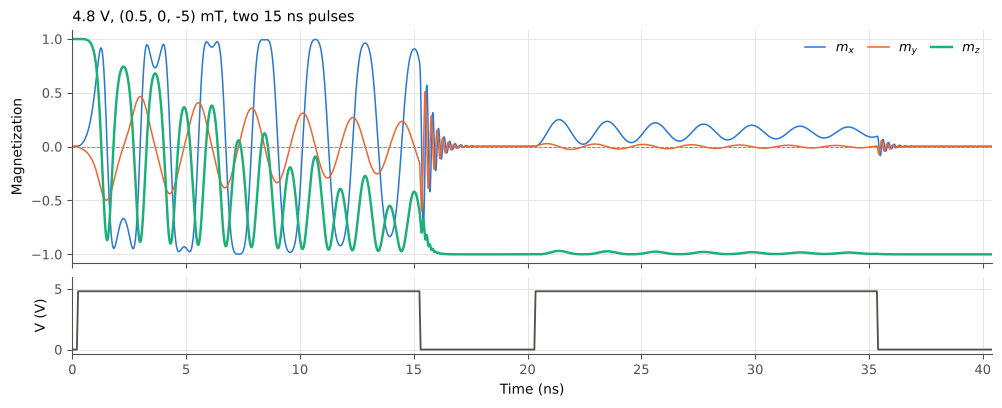

In [11]:
FA = ex.FieldAssisted()
print(f"mu0 H_sw(0) = {1e3*dev.B_switch_z(0):.1f} mT,  mu0 H_sw({FA.V0} V) = {1e3*dev.B_switch_z(FA.V0):.1f} mT")
r = ex.run_pulse(dev, FA.V0, FA.t_hold, FA.bias, double_gap=FA.gap, post=5e-9)
vp.plot_dynamics(r, (9, 3.6), title="4.8 V, (0.5, 0, -5) mT, two 15 ns pulses");
d = np.load(DATA / "field_assisted_scan.npz")
th, wb = d["t_hold"], d["mz_with_bz"]
first = next(t for t in th if np.all(wb[th >= t] < 0))
print(f"with -5 mT the outcome is -z for every pulse longer than {first*1e9:.1f} ns;"
      f" without it the outcome keeps alternating ({np.sum(np.diff(np.sign(d['mz_no_bz'])) != 0)} flips over 0-20 ns)")